In [89]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

PROCESSED_DIR = Path("..") / "data" / "processed"
FIGURES_DIR = Path("..") / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, MUTED = "#0b0b0b", "#898781"
sns.set_theme(
    style="whitegrid",
    rc={
        "axes.edgecolor": "#c3c2b7",
        "grid.color": "#e1e0d9",
        "axes.labelcolor": INK,
        "text.color": INK,
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
    },
)
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])


def save_fig(fig, name):
    path = FIGURES_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")

In [90]:
county_long = pd.read_csv(PROCESSED_DIR / "county_maize_long.csv")
national_afa = pd.read_csv(PROCESSED_DIR / "national_afa_clean.csv")
national_es = pd.read_csv(PROCESSED_DIR / "national_es_clean.csv")
supply_use = pd.read_csv(PROCESSED_DIR / "supply_use_clean.csv")

## 1. Descriptive statistics

In [91]:
county_long[["area_ha", "production_t", "yield_t_ha"]].describe().round(2)

,area_ha,production_t,yield_t_ha
count,235.00,235.00,235.00
mean,48055.23,78735.58,1.41
std,39809.09,99689.16,0.93
min,54.00,0.00,0.00
25%,17240.00,13361.50,0.73
50%,37894.00,45428.00,1.22
75%,72156.00,92417.50,1.83
max,158761.00,489056.00,4.66


In [92]:
# National totals built from the 47 counties
by_year = county_long.groupby("year").agg(area_ha=("area_ha", "sum"), production_t=("production_t", "sum"))
by_year["yield_t_ha"] = by_year["production_t"] / by_year["area_ha"]
by_year["production_change_pct"] = by_year["production_t"].pct_change() * 100
by_year.round(2)

,area_ha,production_t,yield_t_ha,production_change_pct
year,,,,
2020,2171697,3795175,1.75,NaN
2021,2170503,3311941,1.53,-12.73
2022,2113520,3082220,1.46,-6.94
2023,2430013,4285206,1.76,39.03
2024,2407245,4028320,1.67,-5.99


## 2. National production trend 

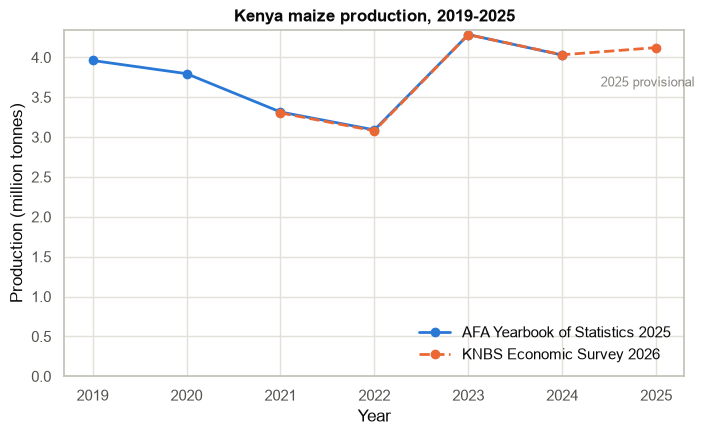

In [93]:
# AFA is the main series and KNBS is shown only as a cross-check
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(national_afa["year"], national_afa["production_t"] / 1e6, marker="o", lw=2, color=BLUE,
        label="AFA Yearbook of Statistics 2025")
ax.plot(national_es["year"], national_es["production_kt"] / 1e3, marker="o", lw=2, ls="--", color=ORANGE,
        label="KNBS Economic Survey 2026")

last = national_es.iloc[-1]
ax.annotate("2025 provisional", xy=(last["year"], last["production_kt"] / 1e3), xytext=(-40, -28),
            textcoords="offset points", fontsize=9, color=MUTED)
ax.set(title="Kenya maize production, 2019-2025", xlabel="Year", ylabel="Production (million tonnes)")
ax.set_ylim(0, None)
ax.legend(frameon=False, loc="lower right")
save_fig(fig, "01_national_production_trend")
plt.show()

Production fell every year from 2019 to 2022, from about 3.96 to 3.09 million tonnes (down 22%), then jumped 39% in 2023, partly because 17.5% more land was planted.

In [94]:
# Year-on-year change (AFA)
trend = national_afa[["year", "area_ha", "production_t", "yield_bags_ha"]].copy()
trend["area_change_pct"] = trend["area_ha"].pct_change() * 100
trend["production_change_pct"] = trend["production_t"].pct_change() * 100
trend.round(1)

,year,area_ha,production_t,yield_bags_ha,area_change_pct,production_change_pct
0,2019,2196136.0,3960385,20.0,NaN,NaN
1,2020,2171695.0,3795170,19.0,-1.1,-4.2
2,2021,2168603.0,3314430,17.0,-0.1,-12.7
3,2022,2171980.0,3089901,16.0,0.2,-6.8
4,2023,2552931.0,4285206,22.8,17.5,38.7
5,2024,2414535.5,4028320,18.5,-5.4,-6.0


## 3. Production by county

In [95]:
county_summary = county_long.groupby("county").agg(
    avg_area_ha=("area_ha", "mean"),
    avg_production_t=("production_t", "mean"),
    total_area_ha=("area_ha", "sum"),
    total_production_t=("production_t", "sum"),
    small_area_flag=("small_area_flag", "first"),
)
# 5-year yield = total production / total area, so each year counts in proportion to its area
county_summary["yield_t_ha"] = county_summary["total_production_t"] / county_summary["total_area_ha"]
county_summary["share_of_production_pct"] = (
    county_summary["total_production_t"] / county_summary["total_production_t"].sum() * 100
)
county_summary = county_summary.sort_values("avg_production_t", ascending=False)
county_summary.head(10).round(1)

,avg_area_ha,avg_production_t,total_area_ha,total_production_t,small_area_flag,yield_t_ha,share_of_production_pct
county,,,,,,,
Uasin Gishu,107879.2,432318.6,539396,2161593,False,4.0,11.7
Trans Nzoia,111424.2,421625.2,557121,2108126,False,3.8,11.4
Bungoma,91356.4,258706.6,456782,1293533,False,2.8,7.0
Narok,124125.4,258559.0,620627,1292795,False,2.1,7.0
Nakuru,76964.0,216010.0,384820,1080050,False,2.8,5.8
Kakamega,95108.4,197817.6,475542,989088,False,2.1,5.3
Nandi,51497.2,131686.6,257486,658433,False,2.6,3.6
Migori,85180.0,107679.6,425900,538398,False,1.3,2.9
Homa Bay,78377.4,104766.2,391887,523831,False,1.3,2.8


In [96]:
# production's concentration: how many counties account for half or 80% of production
cum_share = county_summary["share_of_production_pct"].cumsum()
print(f"Top 5 counties: {cum_share.iloc[4]:.1f}% of production")
print(f"Top 10 counties: {cum_share.iloc[9]:.1f}% of production")
print(f"Counties needed for half of production: {(cum_share < 50).sum() + 1}")
print(f"Counties needed for 80% of production: {(cum_share < 80).sum() + 1}")

Top 5 counties: 42.9% of production
Top 10 counties: 60.4% of production
Counties needed for half of production: 7
Counties needed for 80% of production: 19


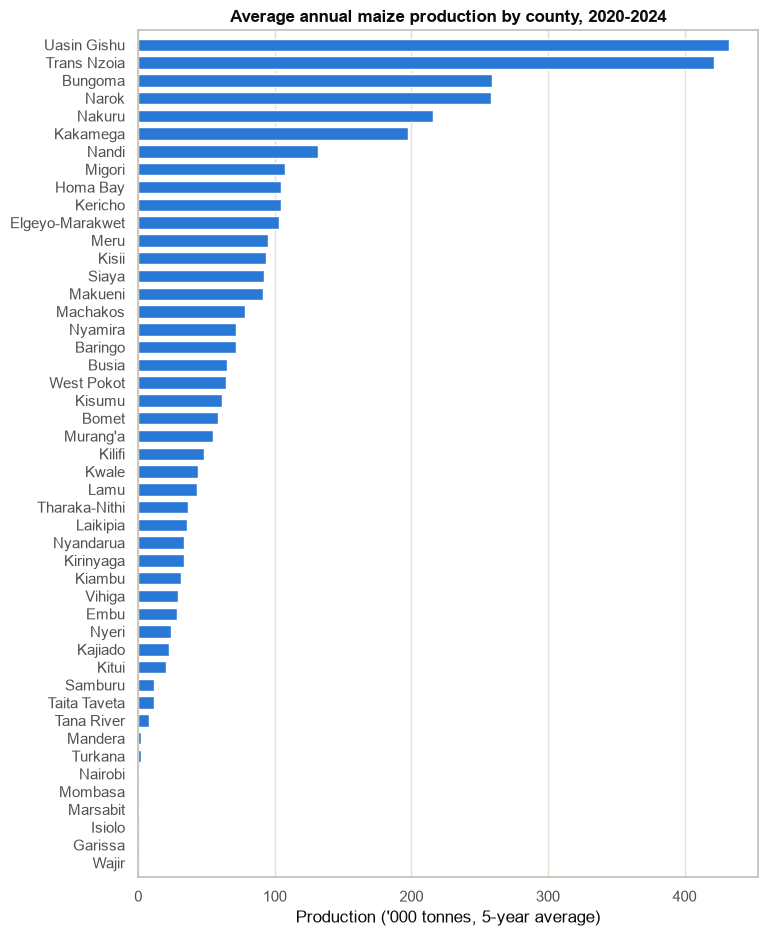

In [97]:
plot_data = county_summary.sort_values("avg_production_t")

fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(plot_data.index, plot_data["avg_production_t"] / 1000, color=BLUE, height=0.7)
ax.set(title="Average annual maize production by county, 2020-2024",
       xlabel="Production ('000 tonnes, 5-year average)", ylabel="")
ax.grid(axis="y", visible=False)
ax.margins(y=0.01)
save_fig(fig, "02_production_by_county")
plt.show()

A handful of counties dominate. Uasin Gishu and Trans Nzoia each average over 420,000 tonnes a year, and just seven counties produce half of Kenya's maize. Counties like Wajir, Garissa, Marsabit, Turkana and Mandera produce very little.

In [98]:
# Change between the first and last year of the 5-year period, ignoring small areas
wide = county_long.pivot(index="county", columns="year", values="production_t")
change = pd.DataFrame({"production_2020_t": wide[2020], "production_2024_t": wide[2024]})
change["change_pct"] = (change["production_2024_t"] / change["production_2020_t"] - 1) * 100
change = change[~county_summary.loc[change.index, "small_area_flag"]].sort_values("change_pct")

print("Largest falls, 2020 to 2024:")
display(change.head(5).round(1))
print("Largest rises, 2020 to 2024:")
display(change.tail(5).round(1))

Largest falls, 2020 to 2024:


,production_2020_t,production_2024_t,change_pct
county,,,
Kisii,132790,41087,-69.1
Kitui,27960,17845,-36.2
Bungoma,317912,207846,-34.6
Makueni,120000,83506,-30.4
Bomet,73610,52714,-28.4


Largest rises, 2020 to 2024:


,production_2020_t,production_2024_t,change_pct
county,,,
Siaya,72351,143979,99.0
Machakos,40927,91910,124.6
Kajiado,15543,40573,161.0
Marsabit,293,1089,271.7
West Pokot,23400,96984,314.5


## 4. Area under maize vs production 

In [99]:
# Pearson: straight-line fit. Spearman: Pearson on ranks, less driven by the largest counties.
x = county_long["area_ha"].to_numpy()
y = county_long["production_t"].to_numpy()

pearson_r = np.corrcoef(x, y)[0, 1]
spearman_rho = county_long["area_ha"].rank().corr(county_long["production_t"].rank())
slope, intercept = np.polyfit(x, y, 1)

print(f"Pearson r:    {pearson_r:.3f}")
print(f"Spearman rho: {spearman_rho:.3f}")
print(f"Slope: {slope:.2f} tonnes per extra hectare")

Pearson r:    0.681
Spearman rho: 0.853
Slope: 1.70 tonnes per extra hectare


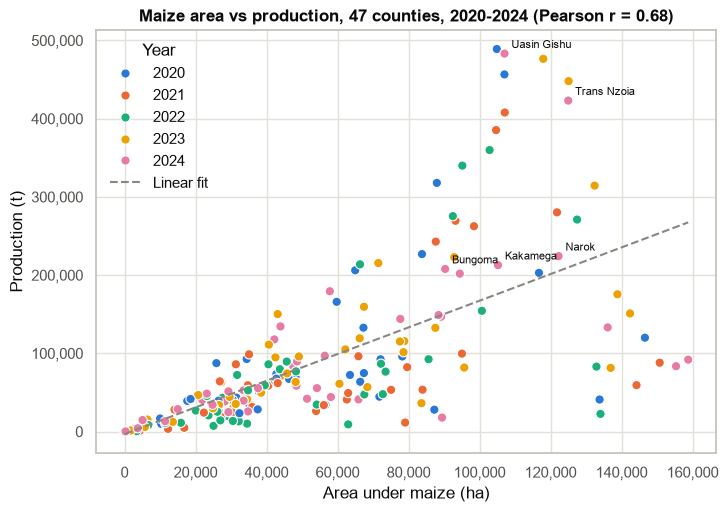

In [100]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=county_long, x="area_ha", y="production_t", hue="year",
                palette=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA], s=45, edgecolor="white", linewidth=0.8, ax=ax)
line_x = np.linspace(0, x.max(), 100)
ax.plot(line_x, slope * line_x + intercept, color=MUTED, lw=1.5, ls="--", label="Linear fit")

# Label the five largest producers at their 2024 point
latest = county_long[county_long["year"] == county_long["year"].max()]
for _, row in latest.nlargest(5, "production_t").iterrows():
    ax.annotate(row["county"], (row["area_ha"], row["production_t"]), xytext=(5, 4),
                textcoords="offset points", fontsize=8, color=INK)

ax.set(title=f"Maize area vs production, 47 counties, 2020-2024 (Pearson r = {pearson_r:.2f})",
       xlabel="Area under maize (ha)", ylabel="Production (t)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.legend(title="Year", frameon=False)
save_fig(fig, "03_area_vs_production")
plt.show()

More land generally means more maize, but the spread widens as area grows. Above about 120,000 ha, some counties harvest over 400,000 tonnes (Uasin Gishu, Trans Nzoia) while others, such as Makueni and Machakos, harvest under 100,000 tonnes from similar or larger areas. That is why the straight-line correlation (0.68) is weaker than the rank correlation (0.85).

## 5. Yield by county 

In [101]:
overall_yield = county_summary["total_production_t"].sum() / county_summary["total_area_ha"].sum()
print(f"Average yield, all counties, 2020-2024: {overall_yield:.2f} t/ha ({overall_yield * 1000 / 90:.1f} bags/ha)")

ranked = county_summary[~county_summary["small_area_flag"]].sort_values("yield_t_ha", ascending=False).copy()

# Year-to-year stability: coefficient of variation (std / mean) of each county's yearly yield
yearly_yield = county_long.pivot(index="county", columns="year", values="yield_t_ha")
ranked["yield_cv_pct"] = (yearly_yield.std(axis=1) / yearly_yield.mean(axis=1) * 100).loc[ranked.index]

cols = ["avg_area_ha", "avg_production_t", "yield_t_ha", "yield_cv_pct"]
print(f"Counties ranked: {len(ranked)}")
print("Highest yields:")
display(ranked[cols].head(10).round(2))
print("Lowest yields:")
display(ranked[cols].tail(10).round(2))

Average yield, all counties, 2020-2024: 1.64 t/ha (18.2 bags/ha)
Counties ranked: 42
Highest yields:


,avg_area_ha,avg_production_t,yield_t_ha,yield_cv_pct
county,,,,
Uasin Gishu,107879.2,432318.6,4.01,10.38
Trans Nzoia,111424.2,421625.2,3.78,13.26
Elgeyo-Marakwet,34847.0,102755.0,2.95,16.90
Bungoma,91356.4,258706.6,2.83,18.51
Nakuru,76964.0,216010.0,2.81,15.45
Kericho,38909.2,104588.0,2.69,12.87
Nandi,51497.2,131686.6,2.56,17.31
Narok,124125.4,258559.0,2.08,13.52
Kakamega,95108.4,197817.6,2.08,27.91


Lowest yields:


,avg_area_ha,avg_production_t,yield_t_ha,yield_cv_pct
county,,,,
Murang'a,63896.4,54531.6,0.85,15.22
Nyeri,28227.4,24013.6,0.85,27.56
Embu,34962.2,28618.2,0.82,41.42
Turkana,2526.4,1947.2,0.77,49.98
Mandera,3292.8,2335.2,0.71,34.63
Kilifi,69108.0,48452.2,0.70,21.93
Makueni,144489.4,91180.0,0.63,17.26
Machakos,141927.0,78049.6,0.55,78.54
Marsabit,1257.2,353.6,0.28,105.11


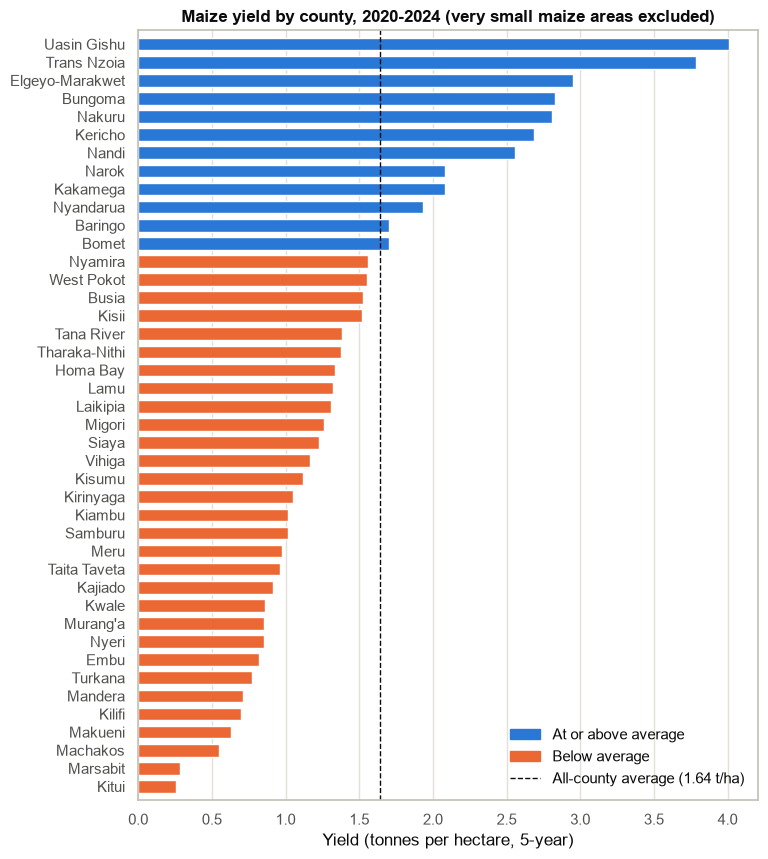

In [102]:
plot_data = ranked.sort_values("yield_t_ha")
colors = np.where(plot_data["yield_t_ha"] >= overall_yield, BLUE, ORANGE)

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(plot_data.index, plot_data["yield_t_ha"], color=colors, height=0.7)
avg_line = ax.axvline(overall_yield, color=INK, lw=1, ls="--")
ax.set(title="Maize yield by county, 2020-2024 (very small maize areas excluded)",
       xlabel="Yield (tonnes per hectare, 5-year)", ylabel="")
ax.grid(axis="y", visible=False)
ax.margins(y=0.01)
handles = [plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)]
ax.legend([*handles, avg_line], ["At or above average", "Below average", f"All-county average ({overall_yield:.2f} t/ha)"],
          frameon=False, loc="lower right")
save_fig(fig, "04_yield_by_county")
plt.show()

Yield ranges from 4.01 t/ha in Uasin Gishu to 0.26 t/ha in Kitui, roughly a 15-fold difference, against an all-county average of 1.64 t/ha. The top of the list is mostly Rift Valley and western counties. The bottom includes several eastern counties (Kitui, Machakos, Makueni, Embu) along with Kilifi, Murang'a and Nyeri.

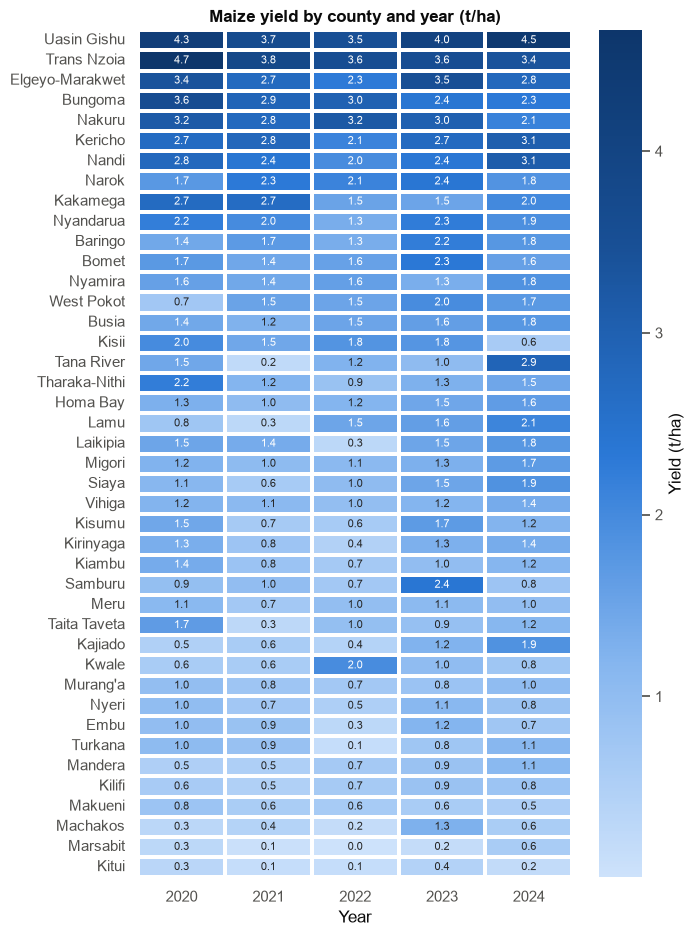

In [103]:
# Heatmap: yield for every county and year, sorted by 5-year yield
heat = yearly_yield.loc[ranked.index]

fig, ax = plt.subplots(figsize=(7, 11))
sns.heatmap(heat, cmap=SEQ_BLUE, annot=True, fmt=".1f", annot_kws={"size": 8},
            linewidths=1.5, linecolor="white", cbar_kws={"label": "Yield (t/ha)"}, ax=ax)
ax.set(title="Maize yield by county and year (t/ha)", xlabel="Year", ylabel="")
save_fig(fig, "05_yield_heatmap")
plt.show()

Uasin Gishu and Trans Nzoia stay above 3.4 t/ha in every year, so their lead is consistent rather than one good season. Further down, yields jump around much more. Tana River went from 0.2 t/ha in 2021 to 2.9 in 2024, and several counties had a very poor 2022 (Laikipia 0.3, Embu 0.3, Turkana 0.1).

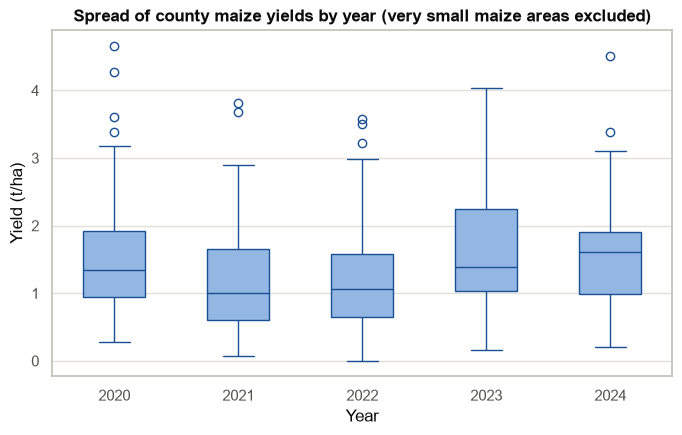

In [104]:
# Distribution of county yields in each year
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=county_long[~county_long["small_area_flag"]], x="year", y="yield_t_ha",
            color="#86b6ef", linecolor="#184f95", width=0.5, ax=ax)
ax.set(title="Spread of county maize yields by year (very small maize areas excluded)",
       xlabel="Year", ylabel="Yield (t/ha)")
save_fig(fig, "06_yield_distribution_by_year")
plt.show()

The typical (median) county yield was lowest in 2021 and 2022, around 1 t/ha, and highest in 2024 at about 1.6 t/ha. The dots above the boxes are the top counties which are led by Uasin Gishu and Trans Nzoia.

In [105]:
# County-based yield vs AFA reported national yield, both in 90-kg bags per hectare
yield_compare = pd.DataFrame({
    "county_based_bags_ha": by_year["yield_t_ha"] * 1000 / 90,
    "afa_reported_bags_ha": national_afa.set_index("year")["yield_bags_ha"],
}).dropna()
yield_compare.round(2)

,county_based_bags_ha,afa_reported_bags_ha
year,,
2020,19.42,19.00
2021,16.95,17.00
2022,16.20,16.00
2023,19.59,22.80
2024,18.59,18.53


## 6. High and low production and productivity counties

In [106]:
# Split counties at the median area and yield; 'large area, low yield' is where better yields add most
median_area = ranked["avg_area_ha"].median()
median_yield = ranked["yield_t_ha"].median()

large = ranked["avg_area_ha"] >= median_area
high = ranked["yield_t_ha"] >= median_yield
groups = ["Large area, high yield", "Large area, low yield", "Smaller area, high yield", "Smaller area, low yield"]
ranked["group"] = np.select([large & high, large & ~high, ~large & high], groups[:3], default=groups[3])

for group in groups:
    members = ranked.index[ranked["group"] == group].tolist()
    print(f"{group} ({len(members)}): {', '.join(members)}")

Large area, high yield (11): Uasin Gishu, Trans Nzoia, Bungoma, Nakuru, Nandi, Narok, Kakamega, Nyamira, Busia, Kisii, Homa Bay
Large area, low yield (10): Migori, Siaya, Kisumu, Meru, Kwale, Murang'a, Kilifi, Makueni, Machakos, Kitui
Smaller area, high yield (10): Elgeyo-Marakwet, Kericho, Nyandarua, Baringo, Bomet, West Pokot, Tana River, Tharaka-Nithi, Lamu, Laikipia
Smaller area, low yield (11): Vihiga, Kirinyaga, Kiambu, Samburu, Taita Taveta, Kajiado, Nyeri, Embu, Turkana, Mandera, Marsabit


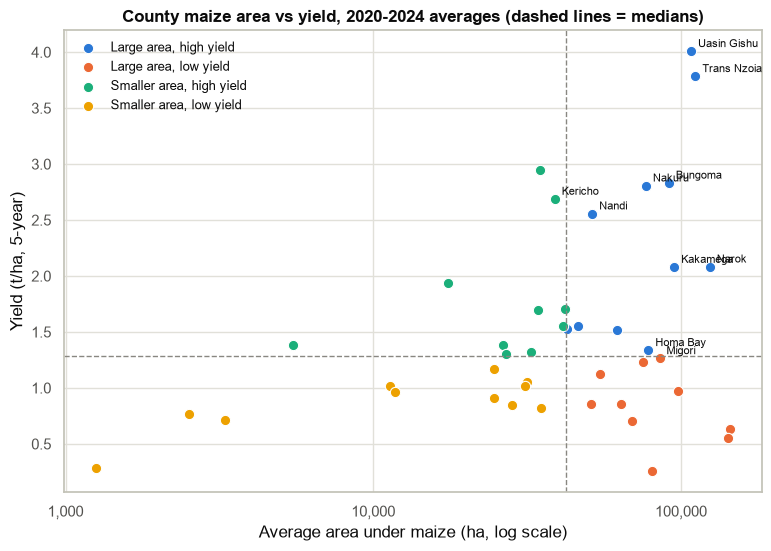

In [107]:
fig, ax = plt.subplots(figsize=(9, 6))
for group, color in zip(groups, [BLUE, ORANGE, AQUA, YELLOW]):
    sub = ranked[ranked["group"] == group]
    ax.scatter(sub["avg_area_ha"], sub["yield_t_ha"], s=55, color=color, edgecolor="white", linewidth=0.8,
               label=group)
ax.axvline(median_area, color=MUTED, lw=1, ls="--")
ax.axhline(median_yield, color=MUTED, lw=1, ls="--")
ax.set_xscale("log")

for name, row in ranked.nlargest(10, "avg_production_t").iterrows():
    ax.annotate(name, (row["avg_area_ha"], row["yield_t_ha"]), xytext=(5, 3), textcoords="offset points",
                fontsize=8)

ax.set(title="County maize area vs yield, 2020-2024 averages (dashed lines = medians)",
       xlabel="Average area under maize (ha, log scale)", ylabel="Yield (t/ha, 5-year)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.legend(frameon=False, fontsize=9, loc="upper left")
save_fig(fig, "07_area_vs_yield_groups")
plt.show()

The bottom-right group is the one to look at. Counties with large maize areas but below-median yields (Migori, Siaya, Kisumu, Meru, Kwale, Murang'a, Kilifi, Makueni, Machakos and Kitui). Raising yields there would add the most maize without planting more land.

In [108]:
summary_out = county_summary.join(ranked[["yield_cv_pct", "group"]])
summary_out.round(3).to_csv(PROCESSED_DIR / "county_summary.csv")

## 7. National supply and use, 2024 vs 2025 

In [82]:
# Only 2024 and 2025 exist, so this is a comparison, not a trend. 2025 is provisional.
labels = {"food_kt": "Food", "feed_kt": "Feed", "losses_kt": "Losses", "seed_kt": "Seed",
          "processed_kt": "Processed", "other_uses_kt": "Other uses"}
su = supply_use.set_index("year")
uses = su[list(labels)].rename(columns=labels)
shares = uses.div(su["domestic_supply_kt"], axis=0) * 100

print("Share of domestic supply (%):")
display(shares.round(1))

su_ratios = pd.DataFrame({
    "imports_share_of_supply_pct": su["imports_kt"] / su["domestic_supply_kt"] * 100,
    "self_sufficiency_pct": su["production_kt"] / su["domestic_supply_kt"] * 100,
})
su_ratios.round(1)

Share of domestic supply (%):


,Food,Feed,Losses,Seed,Processed,Other uses
year,,,,,,
2024,78.2,15.0,1.9,1.7,1.0,2.1
2025,93.3,0.0,2.7,2.0,1.1,0.9


,imports_share_of_supply_pct,self_sufficiency_pct
year,,
2024,9.2,100.6
2025,14.9,116.2


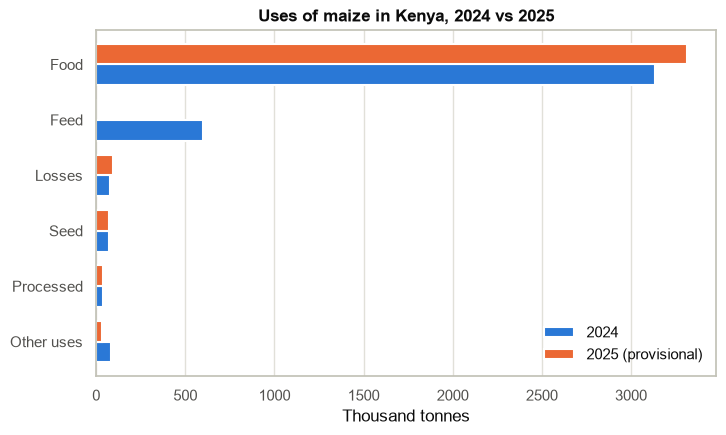

In [83]:
plot_data = uses.T.iloc[::-1]
plot_data.columns = [f"{y}{' (provisional)' if y == 2025 else ''}" for y in plot_data.columns]

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_data.plot(kind="barh", color=[BLUE, ORANGE], width=0.75, ax=ax, edgecolor="white", linewidth=1.5)
ax.set(title="Uses of maize in Kenya, 2024 vs 2025", xlabel="Thousand tonnes", ylabel="")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
save_fig(fig, "08_supply_use_comparison")
plt.show()

Food is by far the biggest use in both years. Feed drops from 601,000 tonnes in 2024 to zero in 2025, which is why food's share jumps from 78% to 93%. That zero may be a gap in the data rather than a real change, and 2025 is provisional.

## 8. Price trends

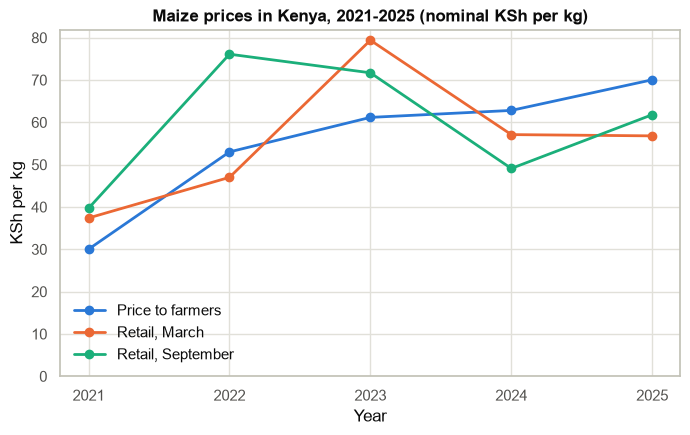

,year,farmer_ksh_kg,retail_march_ksh_kg,retail_sept_ksh_kg
0,2021,30.0,37.4,39.7
1,2022,53.0,47.0,76.1
2,2023,61.2,79.4,71.7
3,2024,62.8,57.1,49.1
4,2025,70.1,56.8,61.8


In [ ]:
# Nominal price. Farmer price converted to KSh/kg to compare with retail.
prices = pd.DataFrame({
    "year": national_es["year"],
    "farmer_ksh_kg": national_es["farmer_price_ksh_100kg"] / 100,
    "retail_march_ksh_kg": national_es["retail_price_march_ksh_kg"],
    "retail_sept_ksh_kg": national_es["retail_price_sept_ksh_kg"],
})

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(prices["year"], prices["farmer_ksh_kg"], marker="o", lw=2, color=BLUE, label="Price to farmers")
ax.plot(prices["year"], prices["retail_march_ksh_kg"], marker="o", lw=2, color=ORANGE, label="Retail, March")
ax.plot(prices["year"], prices["retail_sept_ksh_kg"], marker="o", lw=2, color=AQUA, label="Retail, September")
ax.set(title="Maize prices in Kenya, 2021-2025 (nominal KSh per kg)", xlabel="Year", ylabel="KSh per kg")
ax.set_xticks(prices["year"])
ax.set_ylim(0, None)
ax.legend(frameon=False)
save_fig(fig, "09_price_trends")
plt.show()
prices.round(1)

The price paid to farmers more than doubled in nominal terms between 2021 and 2025, from KSh 30 to KSh 70 per kg. Retail prices peaked in 2022-2023 and then fell, and in 2024 and 2025 they were below the farmer price, which suggests the two series don't measure the same thing. None of these prices are adjusted for inflation.

In [85]:
# The two sources' farmer prices for the years they share
price_compare = pd.merge(
    national_afa[["year", "farmgate_price_ksh_bag"]],
    national_es[["year", "farmer_price_ksh_bag"]],
    on="year",
    how="inner",
).rename(columns={"farmgate_price_ksh_bag": "afa_ksh_bag", "farmer_price_ksh_bag": "knbs_es_ksh_bag"})
price_compare["difference_pct"] = (price_compare["afa_ksh_bag"] / price_compare["knbs_es_ksh_bag"] - 1) * 100
price_compare.round(1)

,year,afa_ksh_bag,knbs_es_ksh_bag,difference_pct
0,2021,2600.0,2702.4,-3.8
1,2022,4500.0,4770.9,-5.7
2,2023,4094.4,5505.0,-25.6
3,2024,3443.2,5653.1,-39.1
